In [1]:
# Requirements: torch, torchvision, opencv-contrib-python-headless (for Selective Search), scikit-learn, pandas, matplotlib
# If cv2.ximgproc is missing, run:  pip install opencv-contrib-python-headless
import os, time, random, pickle, glob, subprocess, math, zipfile
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.ops import nms, box_iou
import matplotlib.pyplot as plt
from matplotlib import patches
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
%matplotlib inline

assert hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation"), \
    "Selective Search needs opencv-contrib: pip install opencv-contrib-python-headless"

# ---------------- configuration ----------------
SEED       = 42
MAX_SIDE   = 300      # images are resized so that the longest side = 300 px (keeps Selective Search fast)
MAX_PROPS  = 800      # max region proposals kept per image
MIN_BOX    = 20       # discard proposals smaller than this (px)
CROP       = 48       # every region is warped to CROP x CROP before the CNN
CTX_PAD    = 0.10     # context padding added around each region before warping (10 % of box size)
POS_IOU    = 0.5      # proposal is a positive if IoU with a GT box >= 0.5
NEG_IOU    = 0.3      # proposal is background if max IoU with all GT boxes < 0.3
N_POS, N_NEG = 40, 60 # regions sampled per training image
EPOCHS, BATCH = 14, 128
CLASSES    = ["raccoon", "kangaroo"]          # class id 0 is reserved for background
NUM_CLS    = len(CLASSES) + 1

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count() or 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__, "| opencv", cv2.__version__)

device: cpu | torch 2.15.0+cu132 | opencv 4.10.0


In [2]:
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

def clone(url, dst):
    if not os.path.isdir(dst):
        subprocess.run(["git", "clone", "--depth", "1", url, dst], check=True)

clone("https://github.com/datitran/raccoon_dataset.git", f"{DATA_DIR}/raccoon_dataset")
clone("https://github.com/experiencor/kangaroo.git",      f"{DATA_DIR}/kangaroo")
print(os.listdir(DATA_DIR))

['raccoon_dataset', 'kangaroo']


In [3]:
def parse_voc_folder(img_dir, ann_dir):
    rows = []
    for xml_file in sorted(glob.glob(os.path.join(ann_dir, "*.xml"))):
        root  = ET.parse(xml_file).getroot()
        fname = root.find("filename").text
        path  = os.path.join(img_dir, fname)
        if not os.path.exists(path):          # a few XMLs may point to a missing/renamed file
            continue
        W = int(float(root.find("size/width").text)); H = int(float(root.find("size/height").text))
        for obj in root.findall("object"):
            bb = obj.find("bndbox")
            rows.append(dict(image_path=path, image_names=os.path.basename(path),
                             class_name=obj.find("name").text.strip().lower(),
                             xmin=int(float(bb.find("xmin").text)), ymin=int(float(bb.find("ymin").text)),
                             xmax=int(float(bb.find("xmax").text)), ymax=int(float(bb.find("ymax").text)),
                             xml_w=W, xml_h=H))
    return pd.DataFrame(rows)

ann = pd.concat([
    parse_voc_folder(f"{DATA_DIR}/raccoon_dataset/images", f"{DATA_DIR}/raccoon_dataset/annotations"),
    parse_voc_folder(f"{DATA_DIR}/kangaroo/images",        f"{DATA_DIR}/kangaroo/annots"),
], ignore_index=True)
ann = ann[ann.class_name.isin(CLASSES)].reset_index(drop=True)
ann.drop(columns=["xml_w", "xml_h"]).to_csv("annotations.csv", index=False)   # same role as train.csv in the manual
ann.drop(columns=["image_path", "xml_w", "xml_h"]).head()

,image_names,class_name,xmin,ymin,xmax,ymax
0,raccoon-1.jpg,raccoon,81,88,522,408
1,raccoon-10.jpg,raccoon,130,2,446,488
2,raccoon-100.jpg,raccoon,548,10,954,520
3,raccoon-101.jpg,raccoon,86,53,400,356
4,raccoon-102.jpg,raccoon,1,1,118,152


rows (bounding boxes): 483
unique images        : 364

boxes per class:
class_name
kangaroo    266
raccoon     217
Name: count, dtype: int64

images per class:
class_name
raccoon     200
kangaroo    164
Name: count, dtype: int64


Premature end of JPEG file



images whose XML size differs from the real size: 0  (boxes are rescaled with the XML size, so this is handled)


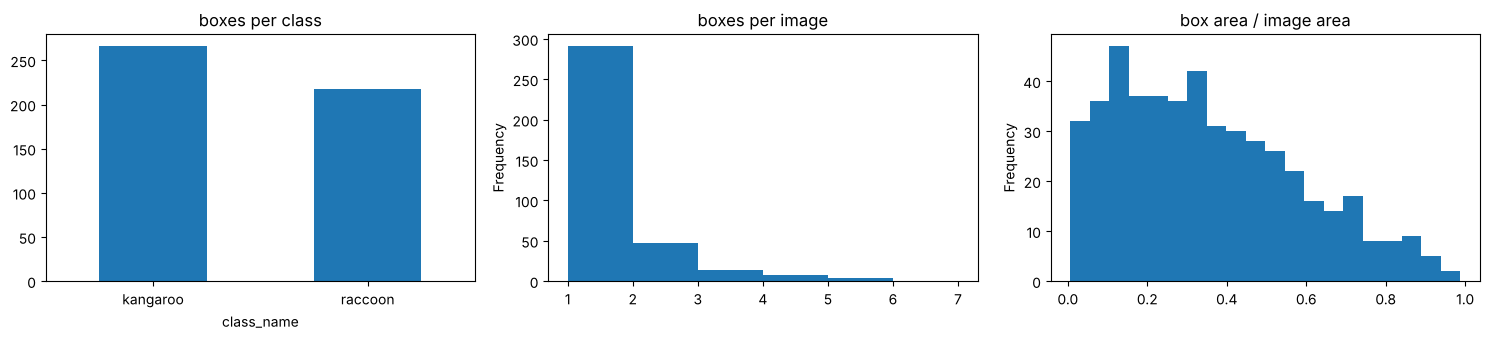

In [4]:
print("rows (bounding boxes):", len(ann))
print("unique images        :", ann.image_path.nunique())
print("\nboxes per class:")
print(ann.class_name.value_counts())
print("\nimages per class:")
print(ann.drop_duplicates("image_path").class_name.value_counts())

# image-size sanity check: does the size stored in the XML match the real image?
chk = ann.drop_duplicates("image_path")
real = [cv2.imread(p).shape[1::-1] for p in chk.image_path]
mismatch = sum((w, h) != (xw, xh) for (w, h), xw, xh in zip(real, chk.xml_w, chk.xml_h))
print(f"\nimages whose XML size differs from the real size: {mismatch}  (boxes are rescaled with the XML size, so this is handled)")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
ann.class_name.value_counts().plot.bar(ax=axs[0], title="boxes per class", rot=0)
ann.groupby("image_path").size().plot.hist(ax=axs[1], bins=range(1, 8), title="boxes per image")
((ann.xmax-ann.xmin)*(ann.ymax-ann.ymin) / (ann.xml_w*ann.xml_h)).plot.hist(ax=axs[2], bins=20, title="box area / image area")
plt.tight_layout(); plt.show()

In [5]:
DATA = {}   # image_path -> dict(img=RGB uint8, boxes=float32 [n,4] (x1,y1,x2,y2), labels=int64 [n])
for path, g in ann.groupby("image_path"):
    bgr = cv2.imread(path); h, w = bgr.shape[:2]
    sc  = MAX_SIDE / max(h, w)
    img = cv2.cvtColor(cv2.resize(bgr, (round(w*sc), round(h*sc)), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
    rw, rh = img.shape[1] / g.xml_w.iloc[0], img.shape[0] / g.xml_h.iloc[0]
    b = np.c_[g.xmin*rw, g.ymin*rh, g.xmax*rw, g.ymax*rh].astype(np.float32)
    b[:, [0, 2]] = b[:, [0, 2]].clip(0, img.shape[1]-1); b[:, [1, 3]] = b[:, [1, 3]].clip(0, img.shape[0]-1)
    ok = ((b[:, 2]-b[:, 0]) > 4) & ((b[:, 3]-b[:, 1]) > 4)
    DATA[path] = dict(img=img, boxes=b[ok], labels=np.array([CLASSES.index(c)+1 for c in g.class_name])[ok].astype(np.int64))
DATA = {p: d for p, d in DATA.items() if len(d["boxes"])}

img_df = pd.DataFrame({"path": list(DATA), "cls": [CLASSES[d["labels"][0]-1] for d in DATA.values()]})
train_p, rest_p = train_test_split(img_df, test_size=0.30, stratify=img_df.cls, random_state=SEED)
val_p,   test_p = train_test_split(rest_p, test_size=0.50, stratify=rest_p.cls, random_state=SEED)
TRAIN, VAL, TEST = train_p.path.tolist(), val_p.path.tolist(), test_p.path.tolist()
print(f"images  train/val/test = {len(TRAIN)}/{len(VAL)}/{len(TEST)}")
for name, s in [("train", TRAIN), ("val", VAL), ("test", TEST)]:
    print(f"  {name:5s}", pd.Series([CLASSES[l-1] for p in s for l in DATA[p]['labels']]).value_counts().to_dict())

Premature end of JPEG file


images  train/val/test = 254/55/55
  train {'kangaroo': 186, 'raccoon': 150}
  val   {'kangaroo': 36, 'raccoon': 35}
  test  {'kangaroo': 44, 'raccoon': 32}


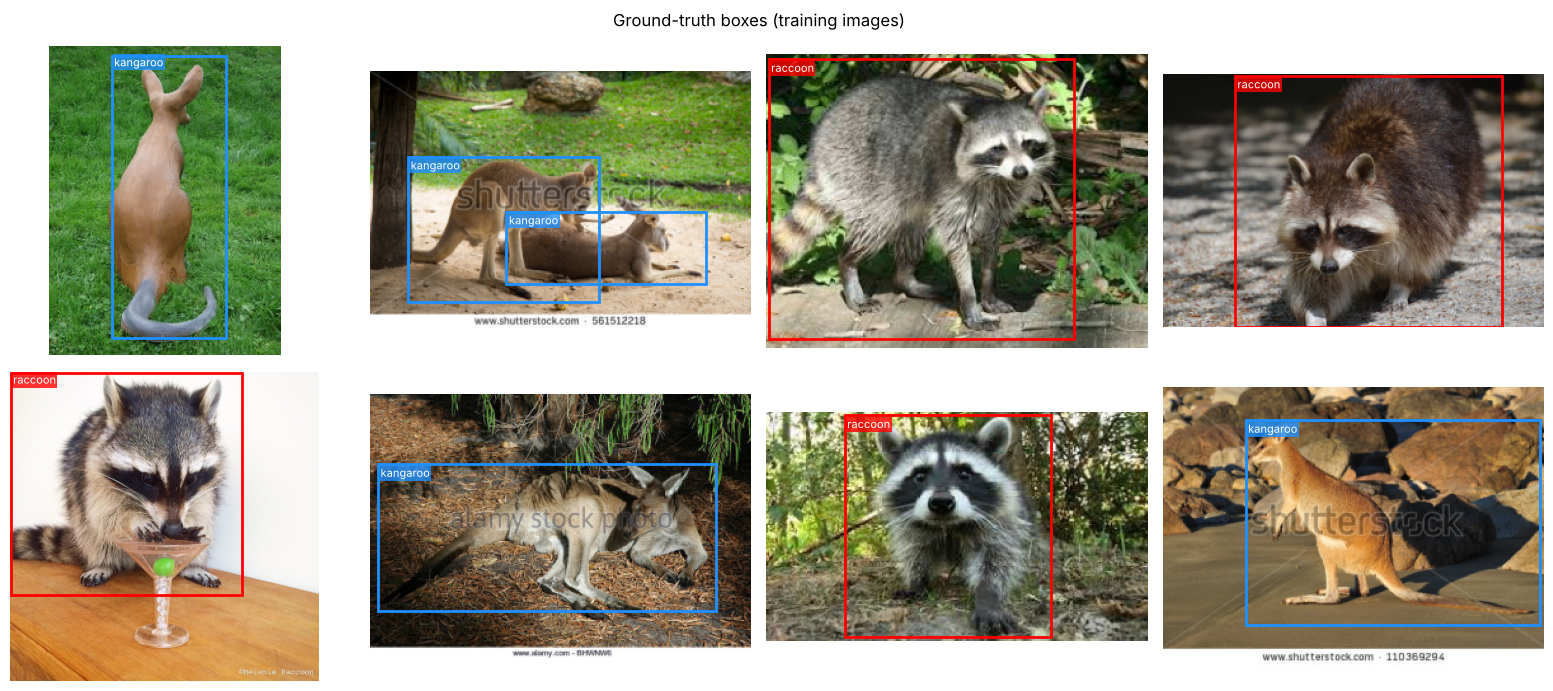

In [6]:
COLORS = {"raccoon": "red", "kangaroo": "dodgerblue"}
def draw(ax, img, boxes, names, scores=None, ls="-", lw=2):
    ax.imshow(img); ax.axis("off")
    for i, (b, n) in enumerate(zip(boxes, names)):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=COLORS[n], lw=lw, ls=ls))
        t = n if scores is None else f"{n} {scores[i]:.2f}"
        ax.text(b[0]+2, b[1]+10, t, color="white", fontsize=8, bbox=dict(fc=COLORS[n], ec="none", pad=1, alpha=.8))

rng0 = np.random.RandomState(1)
sel = list(rng0.choice(TRAIN, 8, replace=False))
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, p in zip(axs.ravel(), sel):
    d = DATA[p]; draw(ax, d["img"], d["boxes"], [CLASSES[l-1] for l in d["labels"]])
plt.suptitle("Ground-truth boxes (training images)"); plt.tight_layout(); plt.show()

In [7]:
def selective_search(img_rgb):
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR))
    ss.switchToSelectiveSearchFast()
    r = ss.process().astype(np.float32)                       # (x, y, w, h)
    b = np.c_[r[:, 0], r[:, 1], r[:, 0]+r[:, 2], r[:, 1]+r[:, 3]]
    w, h = r[:, 2], r[:, 3]
    keep = (w >= MIN_BOX) & (h >= MIN_BOX) & (w/h < 5) & (h/w < 5)
    return b[keep][:MAX_PROPS]

PROP_FILE = "proposals.pkl"
if os.path.exists(PROP_FILE):
    PROPS = pickle.load(open(PROP_FILE, "rb")); print("loaded cached proposals")
else:
    PROPS, t0 = {}, time.time()
    for i, p in enumerate(DATA):
        PROPS[p] = selective_search(DATA[p]["img"])
        if (i+1) % 100 == 0: print(f"  {i+1}/{len(DATA)} images  ({time.time()-t0:.0f}s)")
    pickle.dump(PROPS, open(PROP_FILE, "wb"))
print("avg proposals / image:", np.mean([len(v) for v in PROPS.values()]).round(1))

  100/364 images  (31s)


  200/364 images  (63s)


  300/364 images  (96s)


avg proposals / image: 393.3


proposal recall @ IoU>=0.5: 0.971
proposal recall @ IoU>=0.7: 0.820
proposal recall @ IoU>=0.9: 0.203
mean best IoU per GT box: 0.795


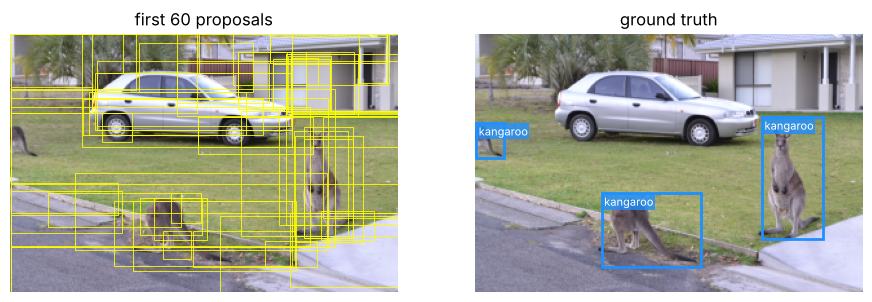

In [8]:
# How good are the proposals?  Recall = fraction of GT boxes covered by at least one proposal with IoU >= thr
best = []
for p in TEST + VAL + TRAIN:
    iou = box_iou(torch.from_numpy(DATA[p]["boxes"]), torch.from_numpy(PROPS[p])).numpy()
    best += list(iou.max(1))
best = np.array(best)
for t in (0.5, 0.7, 0.9):
    print(f"proposal recall @ IoU>={t}: {(best >= t).mean():.3f}")
print("mean best IoU per GT box:", best.mean().round(3))

p = TEST[0]
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow(DATA[p]["img"]); axs[0].axis("off"); axs[0].set_title("first 60 proposals")
for b in PROPS[p][:60]:
    axs[0].add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="yellow", lw=.6))
draw(axs[1], DATA[p]["img"], DATA[p]["boxes"], [CLASSES[l-1] for l in DATA[p]["labels"]]); axs[1].set_title("ground truth")
plt.show()

train regions (21347, 48, 48, 3), val regions (4648, 48, 48, 3)  (1s)
train label counts (0=bg, 1=raccoon, 2=kangaroo): [15200  3470  2677]


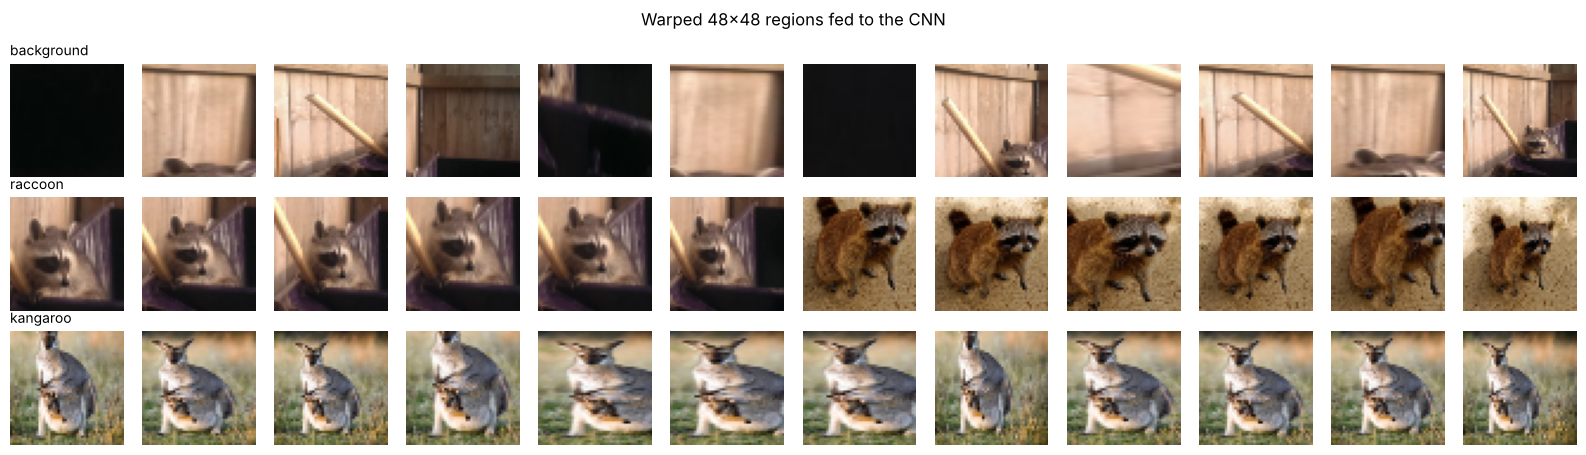

In [9]:
def warp(img, box, size=CROP, pad=CTX_PAD):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = box; bw, bh = x2-x1, y2-y1
    x1, x2 = int(max(0, x1-pad*bw)), int(min(w, x2+pad*bw)+0.5)
    y1, y2 = int(max(0, y1-pad*bh)), int(min(h, y2+pad*bh)+0.5)
    x2, y2 = max(x2, x1+2), max(y2, y1+2)
    return cv2.resize(img[y1:y2, x1:x2], (size, size), interpolation=cv2.INTER_LINEAR)

def build_regions(paths, seed, n_pos=N_POS, n_neg=N_NEG):
    rng = np.random.RandomState(seed)
    crops, lab, iou_, box_, gt_ = [], [], [], [], []
    for p in paths:
        d = DATA[p]
        P = np.vstack([PROPS[p], d["boxes"]]).astype(np.float32)
        iou = box_iou(torch.from_numpy(P), torch.from_numpy(d["boxes"])).numpy()
        best, arg = iou.max(1), iou.argmax(1)
        pos = np.where(best >= POS_IOU)[0]; neg = np.where(best < NEG_IOU)[0]
        pos = rng.choice(pos, min(len(pos), n_pos), replace=False)
        neg = rng.choice(neg, min(len(neg), n_neg), replace=False)
        for i in pos:
            crops.append(warp(d["img"], P[i])); lab.append(d["labels"][arg[i]]); iou_.append(best[i])
            box_.append(P[i]); gt_.append(d["boxes"][arg[i]])
        for i in neg:
            crops.append(warp(d["img"], P[i])); lab.append(0); iou_.append(best[i])
            box_.append(P[i]); gt_.append(np.zeros(4, np.float32))
    return dict(x=np.stack(crops), y=np.array(lab), iou=np.array(iou_, np.float32), box=np.stack(box_), gt=np.stack(gt_))

t0 = time.time()
R_TR, R_VA = build_regions(TRAIN, SEED), build_regions(VAL, SEED+1)
print(f"train regions {R_TR['x'].shape}, val regions {R_VA['x'].shape}  ({time.time()-t0:.0f}s)")
print("train label counts (0=bg, 1=raccoon, 2=kangaroo):", np.bincount(R_TR["y"]))

fig, axs = plt.subplots(3, 12, figsize=(16, 4.6))
for r, c in enumerate([0, 1, 2]):
    idx = np.where(R_TR["y"] == c)[0][:12]
    for a, i in zip(axs[r], idx): a.imshow(R_TR["x"][i]); a.axis("off")
    axs[r][0].set_title(["background", "raccoon", "kangaroo"][c], loc="left", fontsize=10)
plt.suptitle("Warped 48x48 regions fed to the CNN"); plt.tight_layout(); plt.show()

In [10]:
class RegionCNN(nn.Module):
    def __init__(self, n_cls=NUM_CLS, feat_dim=256):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(3, 24), blk(24, 48), blk(48, 96), blk(96, 128))   # 48 -> 3
        self.fc   = nn.Sequential(nn.Flatten(), nn.Linear(128*3*3, feat_dim), nn.ReLU(True))
        self.drop = nn.Dropout(0.5)
        self.cls  = nn.Linear(feat_dim, n_cls)
    def forward(self, x, return_feat=False):
        f = self.fc(self.features(x)); out = self.cls(self.drop(f))
        return (out, f) if return_feat else out

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
def prep(u8):                                         # uint8 NHWC -> normalised float NCHW
    return (torch.from_numpy(u8).permute(0, 3, 1, 2).float()/255. - MEAN) / STD

def augment(x):
    B = x.shape[0]
    x = torch.where((torch.rand(B, 1, 1, 1) < 0.5), x.flip(3), x)                         # horizontal flip
    dx, dy = np.random.randint(-3, 4, 2)                                                     # small shift
    x = F.pad(x, (3, 3, 3, 3), mode="replicate")[:, :, 3+dy:3+dy+CROP, 3+dx:3+dx+CROP]
    return x * (1 + 0.4*(torch.rand(B, 1, 1, 1)-0.5)) + 0.4*(torch.rand(B, 1, 1, 1)-0.5)  # contrast / brightness

model = RegionCNN().to(DEVICE)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 459611


epoch  1/14  train loss 0.520 acc 0.784 | val loss 0.473 acc 0.807  (45s)


epoch  2/14  train loss 0.369 acc 0.855 | val loss 0.374 acc 0.855  (90s)


epoch  3/14  train loss 0.308 acc 0.883 | val loss 0.570 acc 0.824  (135s)


epoch  4/14  train loss 0.266 acc 0.901 | val loss 0.905 acc 0.687  (181s)


epoch  5/14  train loss 0.233 acc 0.914 | val loss 0.356 acc 0.867  (229s)


epoch  6/14  train loss 0.189 acc 0.930 | val loss 0.357 acc 0.884  (277s)


... (4 outputs left out)

epoch 11/14  train loss 0.076 acc 0.974 | val loss 0.343 acc 0.897  (514s)


epoch 12/14  train loss 0.062 acc 0.980 | val loss 0.368 acc 0.895  (560s)


epoch 13/14  train loss 0.051 acc 0.982 | val loss 0.400 acc 0.894  (608s)


epoch 14/14  train loss 0.048 acc 0.983 | val loss 0.406 acc 0.891  (659s)


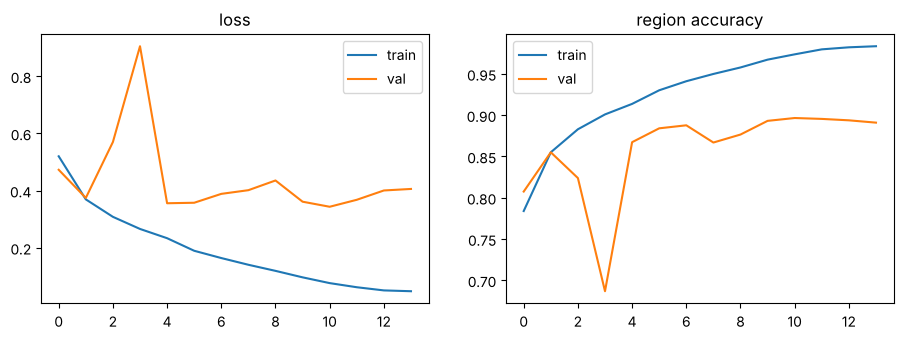

RegionCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(48, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=

In [11]:
WEIGHTS = "region_cnn.pt"
Xva, Yva = prep(R_VA["x"]), torch.from_numpy(R_VA["y"])
hist = dict(tr_loss=[], va_loss=[], tr_acc=[], va_acc=[])

if os.path.exists(WEIGHTS):
    model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE)); print("loaded cached weights")
else:
    N = len(R_TR["y"]); steps = EPOCHS * math.ceil(N / BATCH)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=steps)
    best_acc, t0 = 0, time.time()
    for ep in range(EPOCHS):
        model.train(); perm = np.random.permutation(N); tl = tc = 0
        for i in range(0, N, BATCH):
            idx = perm[i:i+BATCH]
            x = augment(prep(R_TR["x"][idx])).to(DEVICE); y = torch.from_numpy(R_TR["y"][idx]).to(DEVICE)
            out = model(x); loss = F.cross_entropy(out, y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tl += loss.item()*len(idx); tc += (out.argmax(1) == y).sum().item()
        model.eval()
        with torch.no_grad():
            vo = torch.cat([model(Xva[i:i+512].to(DEVICE)).cpu() for i in range(0, len(Xva), 512)])
        va_loss, va_acc = F.cross_entropy(vo, Yva).item(), (vo.argmax(1) == Yva).float().mean().item()
        for k, v in zip(hist, (tl/N, va_loss, tc/N, va_acc)): hist[k].append(v)
        if va_acc > best_acc: best_acc = va_acc; torch.save(model.state_dict(), WEIGHTS)
        print(f"epoch {ep+1:2d}/{EPOCHS}  train loss {tl/N:.3f} acc {tc/N:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}  ({time.time()-t0:.0f}s)")
    model.load_state_dict(torch.load(WEIGHTS, map_location=DEVICE))
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
    axs[0].plot(hist["tr_loss"], label="train"); axs[0].plot(hist["va_loss"], label="val"); axs[0].set_title("loss"); axs[0].legend()
    axs[1].plot(hist["tr_acc"], label="train"); axs[1].plot(hist["va_acc"], label="val"); axs[1].set_title("region accuracy"); axs[1].legend()
    plt.show()
model.eval()

In [12]:
@torch.no_grad()
def extract(crops, bs=512):
    probs, feats = [], []
    for i in range(0, len(crops), bs):
        lo, f = model(prep(crops[i:i+bs]).to(DEVICE), return_feat=True)
        probs.append(F.softmax(lo, 1).cpu().numpy()); feats.append(f.cpu().numpy())
    return np.concatenate(probs), np.concatenate(feats)

_, F_TR = extract(R_TR["x"])
scaler = StandardScaler().fit(F_TR)
Z_TR = scaler.transform(F_TR)
print("train feature matrix:", Z_TR.shape)

def train_svms(C):
    svms = {}
    for c in range(1, NUM_CLS):
        pos = (R_TR["y"] == c) & (R_TR["iou"] >= 0.7)
        neg = (R_TR["y"] != c)
        m = pos | neg
        svms[c] = LinearSVC(C=C, class_weight="balanced", max_iter=20000).fit(Z_TR[m], pos[m])
    return svms

def box_targets(P, G):
    pw, ph = P[:, 2]-P[:, 0], P[:, 3]-P[:, 1]; px, py = P[:, 0]+pw/2, P[:, 1]+ph/2
    gw, gh = G[:, 2]-G[:, 0], G[:, 3]-G[:, 1]; gx, gy = G[:, 0]+gw/2, G[:, 1]+gh/2
    return np.c_[(gx-px)/pw, (gy-py)/ph, np.log(gw/pw), np.log(gh/ph)]

def apply_deltas(P, d):
    pw, ph = P[:, 2]-P[:, 0], P[:, 3]-P[:, 1]; px, py = P[:, 0]+pw/2, P[:, 1]+ph/2
    d = np.clip(d, -4, 4); cx, cy = px+d[:, 0]*pw, py+d[:, 1]*ph; w, h = pw*np.exp(d[:, 2]), ph*np.exp(d[:, 3])
    return np.c_[cx-w/2, cy-h/2, cx+w/2, cy+h/2].astype(np.float32)

def train_regressors(alpha):
    regs = {}
    for c in range(1, NUM_CLS):
        m = (R_TR["y"] == c) & (R_TR["iou"] >= 0.6)
        regs[c] = Ridge(alpha=alpha).fit(Z_TR[m], box_targets(R_TR["box"][m], R_TR["gt"][m]))
    return regs

train feature matrix: (21347, 256)


In [13]:
def image_cache(paths):
    """Run proposals -> warp -> CNN once per image (reused for every SVM/regressor setting)."""
    cache = {}
    for p in paths:
        P = PROPS[p]; crops = np.stack([warp(DATA[p]["img"], b) for b in P])
        probs, feats = extract(crops)
        cache[p] = dict(boxes=P, probs=probs, Z=scaler.transform(feats))
    return cache

def detect(cache, score_fn, regs=None, thr=0.0, nms_iou=0.3):
    dets = []
    for p, c in cache.items():
        H, W = DATA[p]["img"].shape[:2]
        S = score_fn(c)                                   # [n_props, n_classes]
        for k in range(1, NUM_CLS):
            s = S[:, k-1]; m = s > thr
            if not m.any(): continue
            B = c["boxes"][m]
            if regs is not None: B = apply_deltas(B, regs[k].predict(c["Z"][m]))
            B[:, [0, 2]] = B[:, [0, 2]].clip(0, W-1); B[:, [1, 3]] = B[:, [1, 3]].clip(0, H-1)
            keep = nms(torch.from_numpy(B), torch.from_numpy(s[m].astype(np.float32)), nms_iou).numpy()
            dets += [(p, k, float(s[m][i]), B[i]) for i in keep]
    return dets

def voc_ap(rec, prec):
    mrec, mpre = np.r_[0, rec, 1], np.r_[0, prec, 0]
    for i in range(len(mpre)-2, -1, -1): mpre[i] = max(mpre[i], mpre[i+1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx+1]-mrec[idx]) * mpre[idx+1]))

def evaluate(dets, paths, iou_thr=0.5):
    aps = {}
    for c in range(1, NUM_CLS):
        gts  = {p: DATA[p]["boxes"][DATA[p]["labels"] == c] for p in paths}
        npos = sum(len(g) for g in gts.values())
        D = sorted([d for d in dets if d[1] == c], key=lambda d: -d[2])
        used = {p: np.zeros(len(g), bool) for p, g in gts.items()}
        tp = np.zeros(len(D)); fp = np.zeros(len(D))
        for i, (p, _, s, b) in enumerate(D):
            g = gts[p]
            if len(g):
                ious = box_iou(torch.from_numpy(b[None]), torch.from_numpy(g)).numpy()[0]
                j = ious.argmax()
                if ious[j] >= iou_thr and not used[p][j]: tp[i] = 1; used[p][j] = True; continue
            fp[i] = 1
        tp, fp = np.cumsum(tp), np.cumsum(fp)
        aps[CLASSES[c-1]] = voc_ap(tp/max(npos, 1), tp/np.maximum(tp+fp, 1e-9)) if len(D) else 0.0
    aps["mAP"] = float(np.mean([aps[c] for c in CLASSES]))
    return aps

t0 = time.time()
C_VA = image_cache(VAL)
print(f"val cache built ({time.time()-t0:.0f}s, {sum(len(v['boxes']) for v in C_VA.values())} regions)")

val cache built (15s, 20004 regions)


In [14]:
svm_fn = lambda svms: (lambda c: np.stack([svms[k].decision_function(c["Z"]) for k in range(1, NUM_CLS)], 1))

rows = []
for C in (0.001, 0.01, 0.1, 1.0):
    svms = train_svms(C)
    r = evaluate(detect(C_VA, svm_fn(svms), None, thr=-0.5), VAL)
    rows.append(dict(C=C, **{k: round(v, 3) for k, v in r.items()}))
print("SVM regularisation sweep (validation, AP@0.5, no box regression)")
display(pd.DataFrame(rows))
BEST_C = max(rows, key=lambda r: r["mAP"])["C"]; SVMS = train_svms(BEST_C); print("chosen C =", BEST_C)

rows = []
for a in (1, 10, 100, 1000):
    r = evaluate(detect(C_VA, svm_fn(SVMS), train_regressors(a), thr=-0.5), VAL)
    rows.append(dict(alpha=a, **{k: round(v, 3) for k, v in r.items()}))
print("Box-regression ridge sweep (validation)")
display(pd.DataFrame(rows))
BEST_A = max(rows, key=lambda r: r["mAP"])["alpha"]; REGS = train_regressors(BEST_A); print("chosen alpha =", BEST_A)

SVM regularisation sweep (validation, AP@0.5, no box regression)


,C,raccoon,kangaroo,mAP
0,0.001,0.679,0.279,0.479
1,0.010,0.669,0.297,0.483
2,0.100,0.600,0.343,0.472
3,1.000,0.570,0.292,0.431


chosen C = 0.01


Box-regression ridge sweep (validation)


,alpha,raccoon,kangaroo,mAP
0,1,0.697,0.306,0.502
1,10,0.696,0.326,0.511
2,100,0.714,0.307,0.510
3,1000,0.725,0.350,0.537


chosen alpha = 1000


In [15]:
t0 = time.time(); C_TE = image_cache(TEST); print(f"test cache built ({time.time()-t0:.0f}s)")
soft_fn = lambda c: c["probs"][:, 1:]

variants = {
  "(a) CNN softmax only":                 detect(C_TE, soft_fn, None, thr=0.05),
  "(b) CNN + SVMs  (R-CNN w/o bbox reg)": detect(C_TE, svm_fn(SVMS), None, thr=-0.5),
  "(c) CNN + SVMs + bbox regression (full R-CNN)": detect(C_TE, svm_fn(SVMS), REGS, thr=-0.5),
}
res = pd.DataFrame({k: evaluate(d, TEST) for k, d in variants.items()}).T.round(3)
res.columns = [f"AP@0.5 {c}" if c != "mAP" else "mAP@0.5" for c in res.columns]
display(res)

# stricter localisation threshold for the full model
full = variants["(c) CNN + SVMs + bbox regression (full R-CNN)"]
print("full R-CNN at stricter IoU thresholds:", {t: round(evaluate(full, TEST, t)["mAP"], 3) for t in (0.5, 0.6, 0.7)})

test cache built (15s)


,AP@0.5 raccoon,AP@0.5 kangaroo,mAP@0.5
(a) CNN softmax only,0.593,0.288,0.441
(b) CNN + SVMs (R-CNN w/o bbox reg),0.543,0.229,0.386
(c) CNN + SVMs + bbox regression (full R-CNN),0.631,0.233,0.432


full R-CNN at stricter IoU thresholds: {0.5: 0.432, 0.6: 0.193, 0.7: 0.121}


In [16]:
# image-level sanity check: does the highest-scoring detection have the correct class?
ok = 0
for p in TEST:
    d = [x for x in full if x[0] == p]
    if d: ok += (max(d, key=lambda x: x[2])[1] == DATA[p]["labels"][0])
print(f"image-level class accuracy of top detection: {ok}/{len(TEST)} = {ok/len(TEST):.3f}")
print(f"images with at least one detection: {len({d[0] for d in full})}/{len(TEST)}")

image-level class accuracy of top detection: 50/55 = 0.909
images with at least one detection: 55/55


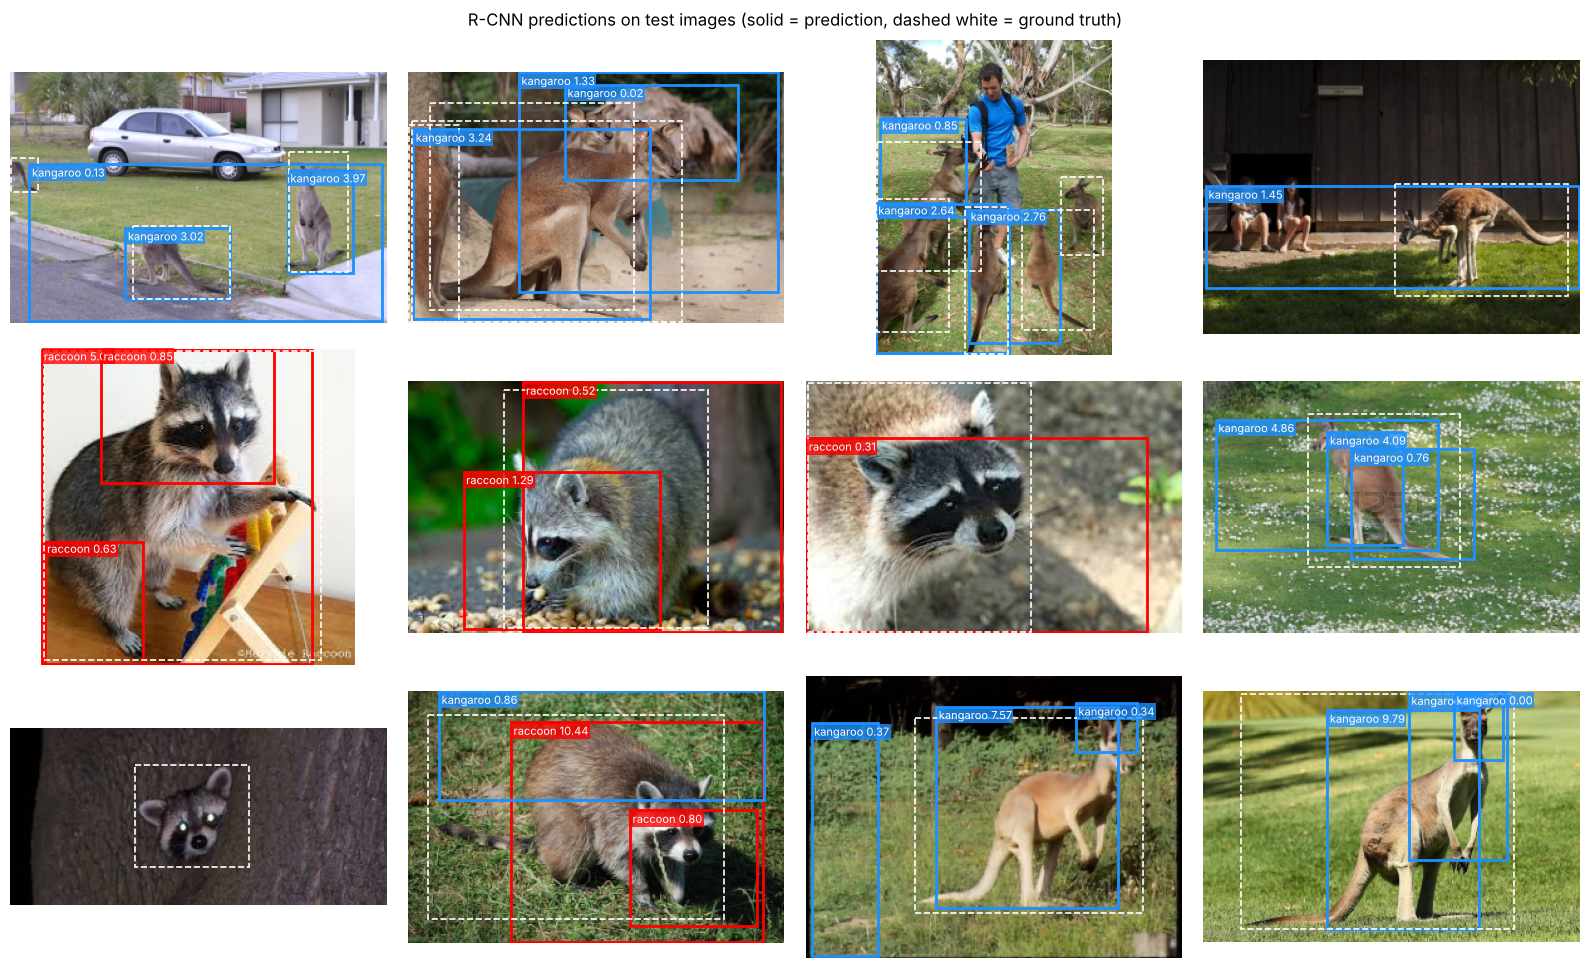

55 prediction images saved to ./predictions


In [17]:
os.makedirs("predictions", exist_ok=True)
def top_dets(p, k=3): return sorted([d for d in full if d[0] == p and d[2] > 0], key=lambda d: -d[2])[:k]

for p in TEST:
    fig, ax = plt.subplots(figsize=(4.5, 3.4)); d = top_dets(p)
    draw(ax, DATA[p]["img"], [x[3] for x in d], [CLASSES[x[1]-1] for x in d], [x[2] for x in d])
    for b in DATA[p]["boxes"]: ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="white", lw=1.2, ls="--"))
    fig.savefig(f"predictions/{os.path.basename(p)}.png", dpi=90, bbox_inches="tight"); plt.close(fig)

fig, axs = plt.subplots(3, 4, figsize=(16, 10))
for ax, p in zip(axs.ravel(), TEST[:12]):
    d = top_dets(p)
    draw(ax, DATA[p]["img"], [x[3] for x in d], [CLASSES[x[1]-1] for x in d], [x[2] for x in d])
    for b in DATA[p]["boxes"]: ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="white", lw=1.2, ls="--"))
plt.suptitle("R-CNN predictions on test images (solid = prediction, dashed white = ground truth)"); plt.tight_layout(); plt.show()
print(len(os.listdir("predictions")), "prediction images saved to ./predictions")

In [18]:
t_ss = t_cnn = t_post = 0; n = 15
for p in TEST[:n]:
    t = time.time(); P = selective_search(DATA[p]["img"]); t_ss += time.time()-t
    t = time.time(); crops = np.stack([warp(DATA[p]["img"], b) for b in P]); _, f = extract(crops); Z = scaler.transform(f); t_cnn += time.time()-t
    t = time.time(); c = dict(boxes=P, Z=Z); _ = detect({p: c}, svm_fn(SVMS), REGS, thr=-0.5); t_post += time.time()-t
print(f"avg per image ({DEVICE}, ~{np.mean([len(PROPS[p]) for p in TEST[:n]]):.0f} proposals): "
      f"selective search {t_ss/n:.2f}s + warp/CNN {t_cnn/n:.2f}s + SVM/regression/NMS {t_post/n:.2f}s = {(t_ss+t_cnn+t_post)/n:.2f}s")

avg per image (cpu, ~344 proposals): selective search 0.28s + warp/CNN 0.22s + SVM/regression/NMS 0.00s = 0.50s
